# 08 · Soporte y resultado principal

**Preguntas que responde:** ¿hay variación de la exposición dentro de cada producto para poder estimar algo?
¿Qué tanto de la corrección de bending (Y = bending real − preset) se explica por el producto, la dimensión y el
programa del Skinpass, por encima del azar? ¿La corona relativa con que el rollo sale del MC4 se asocia con Y,
ajustando por producto, dimensión y mes? ¿Esa asociación es igual en todos los productos?

Implementa las secciones 7, 8.B, 8.C y 8.D del plan congelado. Orden: **soporte antes de estimar**.
Produce la Tabla de soporte y las figuras de resultados R1–R3 del artículo.

In [1]:
import sys
sys.path.insert(0, "..")

import warnings
warnings.filterwarnings("ignore", category=Warning, module="pandas")

import numpy as np
import pandas as pd

from src import inferencia as inf, resultados as res, skinpass as sk
from src import figuras_articulo as fa
from src.config import TABLAS_DIR
from src.resultados import fmt, guardar_cifras
from src.visualizacion import estilo_articulo, guardar_articulo

pd.set_option("display.width", 200, "display.max_columns", 30)
estilo_articulo()
m, pz, rs = sk.construir()
a = sk.analitica(m, "paso4")    # resultado definido
a5 = sk.analitica(m, "paso5")   # además con corona válida
a5["celda_dm"] = a5["dimension"] + " | " + a5["mes_str"]
print(f"Paso 4: {len(a):,} rollos, {a['programa_skp'].nunique()} programas · Paso 5: {len(a5):,} rollos")

Paso 4: 44,272 rollos, 831 programas · Paso 5: 43,208 rollos


## 1. Diagnóstico de soporte (sección 7), antes de cualquier estimación

Por producto: rollos, programas del Skinpass, meses, celdas producto × dimensión × mes con ≥ 5 rollos, variación de
la corona relativa dentro de celda y % con preset = 0. Un producto sin variación de corona dentro de celda no aporta
a la asociación y sale con nota (la regresión con efectos fijos lo excluye de forma automática).

In [2]:
sop = res.soporte_por_producto(a, a5)
sop.round(3).to_csv(TABLAS_DIR / "soporte_por_producto.csv")
resumen = res.soporte_resumen(a, a5, sop)
resumen.round(2).to_csv(TABLAS_DIR / "soporte_resumen.csv", index=False)
fa.tabla_latex(resumen, TABLAS_DIR / "tabla_soporte.tex",
               {"Tipo": "Tipo", "Rollos": "Rollos", "Programas SKP": "Progr.", "Productos": "Prod.",
                "Productos con ≥300 rollos": "Prod. $\\geq$300", "Celdas p×d×m": "Celdas",
                "% rollos en celdas ≥5": "\\% en celdas $\\geq$5", "DE corona rel. dentro de celda (pp)": "DE corona (pp)",
                "% preset = 0": "\\% preset 0"},
               {"Rollos": "{:,.0f}", "Programas SKP": "{:,.0f}", "Productos": "{:,.0f}", "Productos con ≥300 rollos": "{:,.0f}",
                "Celdas p×d×m": "{:,.0f}", "% rollos en celdas ≥5": "{:.1f}", "DE corona rel. dentro de celda (pp)": "{:.2f}",
                "% preset = 0": "{:.1f}"})
sin_soporte = sop[~sop["con_soporte"]]
print(f"Productos sin variación de corona dentro de celda (salen de la asociación): {len(sin_soporte)} "
      f"({int(sin_soporte['rollos'].sum()):,} rollos)")
grandes = sop[sop["rollos"] >= 300]
print(f"Productos con ≥ 300 rollos: {len(grandes)}; mediana de programas por producto {grandes['programas_skp'].median():.0f}; "
      f"todos con soporte: {bool(grandes['con_soporte'].all())}")
resumen.round(2)

Productos sin variación de corona dentro de celda (salen de la asociación): 44 (96 rollos)
Productos con ≥ 300 rollos: 35; mediana de programas por producto 216; todos con soporte: True


,Tipo,Rollos,Programas SKP,Productos,Productos con ≥300 rollos,Celdas p×d×m,% rollos en celdas ≥5,DE corona rel. dentro de celda (pp),% preset = 0
0,CALIENTE,16456,746,152,12,2070,84.61,0.69,11.55
1,DECAPADO,27177,754,234,23,4457,79.65,0.53,11.15
2,FRIO,639,121,31,0,136,77.15,0.38,0.00
3,Total,44272,831,331,35,6137,83.23,0.60,11.14


## 2. Descomposición anidada de Y (sección 8.B)

Fracción de la suma de cuadrados de Y en cada nivel (tipo → producto → dimensión → programa del Skinpass → rollo),
contra lo que el mismo nivel obtendría por azar (100 permutaciones de las etiquetas dentro de la celda padre). El
intervalo del exceso usa mitades de programas (200 réplicas; bitácora del plan, v1.2). Se repite con el programa antes
del producto para mostrar cuánto depende del orden.

In [3]:
desc = res.descomposiciones(a, n_perm=100, n_boot=200)
desc["principal"].to_csv(TABLAS_DIR / "descomposicion_principal.csv", index=False)
desc["orden_programa_primero"].to_csv(TABLAS_DIR / "descomposicion_orden_programa_primero.csv", index=False)
# Transparencia: el bootstrap con reemplazo que pedía el plan v1.1, y por qué se descartó
boot = inf.exceso_sobre_azar(a, "y_corr", res.NIVELES, n_perm=100, n_boot=200, metodo="bootstrap")
boot.to_csv(TABLAS_DIR / "descomposicion_bootstrap_descartado.csv", index=False)
print("Bootstrap con reemplazo (descartado): ¿la réplica media se aleja de la estimación?")
print(boot[["nivel", "exceso", "replicas_media", "exceso_ic_inf", "exceso_ic_sup"]].round(4).to_string(index=False))
print()
for k, t in desc.items():
    print(k); print(t.round(4).to_string(index=False)); print()

Bootstrap con reemplazo (descartado): ¿la réplica media se aleja de la estimación?
       nivel  exceso  replicas_media  exceso_ic_inf  exceso_ic_sup
        tipo  0.0022          0.0024         0.0008         0.0050
    producto  0.0882          0.0998         0.0857         0.1172
   dimension  0.0395          0.0665         0.0581         0.0741
programa_skp  0.2207          0.2030         0.1877         0.2166

principal
       nivel  fraccion_observada  media_nula  p95_nula  exceso  exceso_ic_inf  exceso_ic_sup  replicas_media metodo_ic  rollos  grupos_en_el_nivel
        tipo              0.0022      0.0000    0.0002  0.0022        -0.0001         0.0045          0.0024   mitades   44272                   3
    producto              0.0973      0.0092    0.0102  0.0882         0.0702         0.1061          0.0931   mitades   44272                 417
   dimension              0.0653      0.0258    0.0278  0.0395         0.0306         0.0484          0.0489   mitades   44272    

PosixPath('/Users/emilianolunageorge/Documents/8. TEC/Reto_Ternuim/ternium-matacanes/outputs/figuras/articulo/fig_r1_descomposicion.pdf')

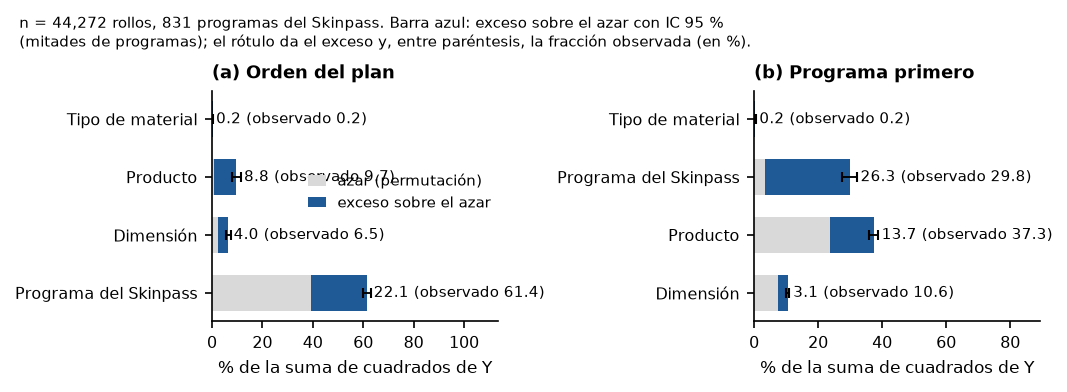

In [4]:
fig = fa.fig_descomposicion(desc["principal"], desc["orden_programa_primero"], len(a), a["programa_skp"].nunique())
guardar_articulo(fig, "fig_r1_descomposicion")

## 3. Asociación ajustada: corona relativa del MC4 → Y (sección 8.C)

`Y ~ corona_rel + desv_temp_enrollado + FE(producto × dimensión × mes)`, errores agrupados por programa del Skinpass
(CR1, contando los efectos fijos absorbidos). Se reporta el efecto por punto porcentual de corona relativa y por una
desviación estándar **dentro de celda**, con IC 95 %, la R² parcial y la curva por deciles dentro de celda. La misma
especificación con el **preset** como resultado comprueba el supuesto S3 (el preset no debería responder a la corona
del rollo).

                                   0       1
variable              corona_rel_pct  dev_te
coef                         -3.9015 -0.2313
se                            1.3717  0.1961
t                            -2.8442 -1.1794
p                             0.0046  0.2386
ic_inf                        -6.594 -0.6163
ic_sup                        -1.209  0.1537
sd_dentro_celda               0.9993   4.954
efecto_por_sd                -3.8987  -1.146
efecto_por_sd_ic_inf         -6.5894 -3.0532
efecto_por_sd_ic_sup         -1.2081  0.7612
r2_parcial                    0.0002     0.0
rollos                         41539   41539
grupos_cluster                   828     828
celdas_fe                       4451    4451
gl_resid                       37086   37086


PosixPath('/Users/emilianolunageorge/Documents/8. TEC/Reto_Ternuim/ternium-matacanes/outputs/figuras/articulo/fig_r2_corona.pdf')

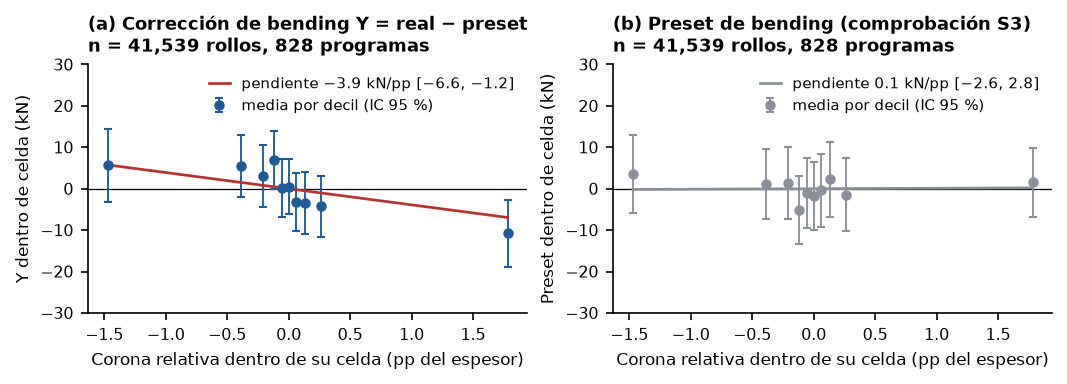

In [5]:
est = res.asociacion(a5)
est_preset = res.asociacion(a5, y="bend_preset")
est.to_csv(TABLAS_DIR / "asociacion_principal.csv", index=False)
print(est.round(4).T)
cy = inf.curva_deciles(a5, "y_corr", "corona_rel_pct", res.FE, res.CLUSTER)
cp = inf.curva_deciles(a5, "bend_preset", "corona_rel_pct", res.FE, res.CLUSTER)
cy.to_csv(TABLAS_DIR / "curva_deciles_corona_y.csv", index=False)
cp.to_csv(TABLAS_DIR / "curva_deciles_corona_preset.csv", index=False)
fig = fa.fig_corona(cy, cp, est.iloc[0], est_preset.iloc[0])
guardar_articulo(fig, "fig_r2_corona")

## 4. Indicadores secundarios con la misma especificación (sección 4)

In [6]:
sec = res.indicadores_secundarios(a5)
sec.to_csv(TABLAS_DIR / "indicadores_secundarios.csv", index=False)
sec[["resultado", "variable", "coef", "ic_inf", "ic_sup", "p", "efecto_por_sd", "rollos", "grupos_cluster"]].round(4)

,resultado,variable,coef,ic_inf,ic_sup,p,efecto_por_sd,rollos,grupos_cluster
0,Bending real (kN),corona_rel_pct,-3.7828,-6.0321,-1.5335,0.0010,-3.7801,41539,828
1,Bending real (kN),dev_te,-0.3576,-0.6627,-0.0525,0.0217,-1.7715,41539,828
2,Defecto de inspector en el Skinpass (pp),corona_rel_pct,-0.2190,-0.4479,0.0099,0.0608,-0.2189,41539,828
3,Defecto de inspector en el Skinpass (pp),dev_te,-0.0086,-0.0367,0.0196,0.5509,-0.0424,41539,828
4,RETENIDO en el Skinpass (pp),corona_rel_pct,-0.1411,-0.4951,0.2129,0.4342,-0.1410,41539,828
5,RETENIDO en el Skinpass (pp),dev_te,-0.0491,-0.1229,0.0247,0.1918,-0.2433,41539,828
6,"Elongación lograda, modo Elongación (%)",corona_rel_pct,0.0001,-0.0017,0.0018,0.9508,0.0001,39455,675
7,"Elongación lograda, modo Elongación (%)",dev_te,-0.0000,-0.0003,0.0003,0.9898,-0.0000,39455,675
8,Preset de bending (kN; comprobación de S3),corona_rel_pct,0.1187,-2.5707,2.8081,0.9310,0.1186,41539,828
9,Preset de bending (kN; comprobación de S3),dev_te,-0.1263,-0.5342,0.2817,0.5437,-0.6256,41539,828


## 5. Heterogeneidad por producto (sección 8.D)

La misma pendiente dentro de cada producto con ≥ 300 rollos (efectos fijos dimensión × mes, errores por programa),
**todas** en una figura con su IC; FDR de Benjamini–Hochberg. Elegir el producto con la pendiente más extrema
sobrestima su efecto (maldición del optimizador; Smith y Winkler, 2006).

35 productos; IC que excluye 0: 1; rechazan con FDR 5 %: 0; pendientes negativas: 27


,producto,tipo,coef,se,ic_inf,ic_sup,p,rollos,programas,rollos_producto,q_bh,rechaza_bh
0,ASTM A 1011 | HSLAS 55 CLASE 1,DECAPADO,-30.045,22.223,-73.978,13.889,0.179,532,142,542,0.696,False
1,GMW3032M-ST-S | HR550LA,DECAPADO,-20.049,20.329,-60.156,20.058,0.325,623,186,642,0.696,False
2,SAE J2340 | HSLAS 420 XF,DECAPADO,-15.512,8.420,-32.076,1.053,0.066,846,321,873,0.696,False
3,ASTM A 1011 | HSLAS 50 CLASE 2,CALIENTE,-15.109,12.329,-39.478,9.259,0.222,365,145,381,0.696,False
4,TER | 1006 GAL,DECAPADO,-14.118,8.483,-30.817,2.582,0.097,999,280,1012,0.696,False
5,GMW3032M-ST-S | HR420LA,DECAPADO,-10.660,9.154,-28.659,7.340,0.245,1343,379,1365,0.696,False
6,TER | 060 XLF,CALIENTE,-9.148,9.998,-28.996,10.700,0.363,322,96,333,0.696,False
7,SAE J403 | 1006,CALIENTE,-8.501,5.669,-19.653,2.651,0.135,1508,328,1536,0.696,False
8,TER | 1010MODIF,CALIENTE,-8.382,4.439,-17.138,0.374,0.061,851,191,864,0.696,False
9,TER | DDQ-COPELAND,DECAPADO,-8.327,7.316,-22.779,6.126,0.257,468,154,476,0.696,False


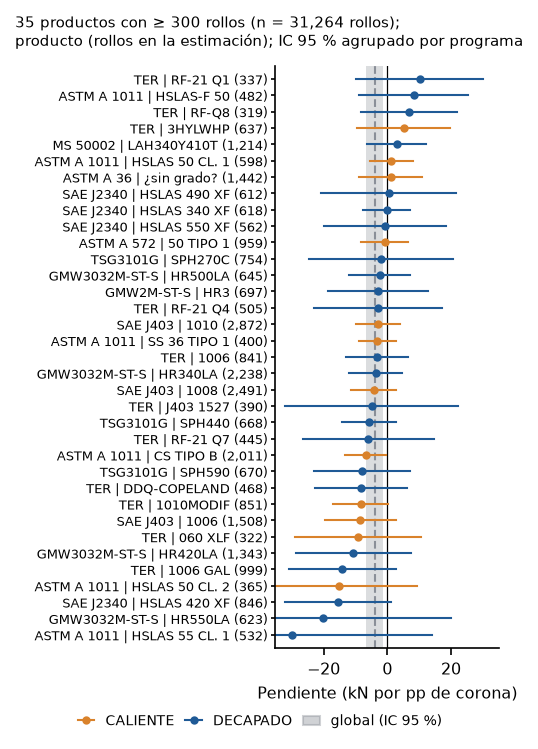

In [7]:
pp = res.pendientes_por_producto(a5, min_rollos=300)
pp.to_csv(TABLAS_DIR / "pendientes_por_producto.csv", index=False)
print(f"{len(pp)} productos; IC que excluye 0: {int(((pp['ic_sup'] < 0) | (pp['ic_inf'] > 0)).sum())}; "
      f"rechazan con FDR 5 %: {int(pp['rechaza_bh'].sum())}; pendientes negativas: {int((pp['coef'] < 0).sum())}")
fig = fa.fig_productos(pp, est.iloc[0])
guardar_articulo(fig, "fig_r3_productos")
pp.round(3)

## 6. Cifras para el texto

In [8]:
P, O = desc["principal"].set_index("nivel"), desc["orden_programa_primero"].set_index("nivel")
e, ep, et = est.iloc[0], est_preset.iloc[0], est.iloc[1]
sb = sec.set_index(["resultado", "variable"])
def sec_c(nombre):
    r = sb.loc[(nombre, "corona_rel_pct")]
    return f"{fmt(r['coef'], 2)} [{fmt(r['ic_inf'], 2)}, {fmt(r['ic_sup'], 2)}]"
c = {}
for niv, k in [("tipo", "Tipo"), ("producto", "Producto"), ("dimension", "Dimension"), ("programa_skp", "Programa")]:
    c[f"Obs{k}"] = fmt(100 * P.loc[niv, "fraccion_observada"], 1)
    c[f"Nula{k}"] = fmt(100 * P.loc[niv, "media_nula"], 1)
    c[f"Exceso{k}"] = fmt(100 * P.loc[niv, "exceso"], 1)
    c[f"Exceso{k}IC"] = f"[{fmt(100 * P.loc[niv, 'exceso_ic_inf'], 1)}, {fmt(100 * P.loc[niv, 'exceso_ic_sup'], 1)}]"
    c[f"ExcesoAlt{k}"] = fmt(100 * O.loc[niv, "exceso"], 1)
c["ObsRollo"] = fmt(100 * (1 - P["fraccion_observada"].sum()), 1)
c["ExcesoProdDim"] = fmt(100 * (P.loc["producto", "exceso"] + P.loc["dimension", "exceso"]), 1)
c.update({
    "PendCorona": fmt(e["coef"], 1), "PendCoronaIC": f"[{fmt(e['ic_inf'], 1)}, {fmt(e['ic_sup'], 1)}]",
    "PendCoronaP": f"{e['p']:.3f}", "PendCoronaT": fmt(e["t"], 2),
    "PendCoronaSD": fmt(e["efecto_por_sd"], 1), "PendCoronaSDIC": f"[{fmt(e['efecto_por_sd_ic_inf'], 1)}, {fmt(e['efecto_por_sd_ic_sup'], 1)}]",
    "SDCoronaDentro": fmt(e["sd_dentro_celda"], 2), "RParcialCorona": f"{100 * e['r2_parcial']:.2f}",
    "NAsocRollos": fmt(e["rollos"], 0), "NAsocProgramas": fmt(e["grupos_cluster"], 0), "NAsocCeldas": fmt(e["celdas_fe"], 0),
    "PendTemp": fmt(et["coef"], 2), "PendTempIC": f"[{fmt(et['ic_inf'], 2)}, {fmt(et['ic_sup'], 2)}]",
    "PendPreset": fmt(ep["coef"], 1), "PendPresetIC": f"[{fmt(ep['ic_inf'], 1)}, {fmt(ep['ic_sup'], 1)}]",
    "SecBendReal": sec_c("Bending real (kN)"), "SecDefInsp": sec_c("Defecto de inspector en el Skinpass (pp)"),
    "SecRetenido": sec_c("RETENIDO en el Skinpass (pp)"), "SecElong": sec_c("Elongación lograda, modo Elongación (%)"),
    "PctYPorSD": fmt(100 * abs(e["efecto_por_sd"]) / a5["y_corr"].std(), 1),
    "NProdHet": fmt(len(pp), 0), "NProdHetRollos": fmt(pp["rollos"].sum(), 0),
    "NProdICexcluyeCero": fmt(int(((pp["ic_sup"] < 0) | (pp["ic_inf"] > 0)).sum()), 0),
    "NProdBH": fmt(int(pp["rechaza_bh"].sum()), 0), "NProdNeg": fmt(int((pp["coef"] < 0).sum()), 0),
    "PendProdMin": fmt(pp["coef"].min(), 1), "PendProdMax": fmt(pp["coef"].max(), 1),
    "NSinSoporte": fmt(len(sin_soporte), 0), "NSinSoporteRollos": fmt(int(sin_soporte["rollos"].sum()), 0),
    "NProdGrandes": fmt(len(grandes), 0), "PctRollosProdGrandes": fmt(100 * grandes["rollos"].sum() / len(a), 1),
})
guardar_cifras(c)
c

{'ObsTipo': '0.2',
 'NulaTipo': '0.0',
 'ExcesoTipo': '0.2',
 'ExcesoTipoIC': '[0.0, 0.5]',
 'ExcesoAltTipo': '0.2',
 'ObsProducto': '9.7',
 'NulaProducto': '0.9',
 'ExcesoProducto': '8.8',
 'ExcesoProductoIC': '[7.0, 10.6]',
 'ExcesoAltProducto': '13.7',
 'ObsDimension': '6.5',
 'NulaDimension': '2.6',
 'ExcesoDimension': '4.0',
 'ExcesoDimensionIC': '[3.1, 4.8]',
 'ExcesoAltDimension': '3.1',
 'ObsPrograma': '61.4',
 'NulaPrograma': '39.4',
 'ExcesoPrograma': '22.1',
 'ExcesoProgramaIC': '[20.5, 23.6]',
 'ExcesoAltPrograma': '26.3',
 'ObsRollo': '22.1',
 'ExcesoProdDim': '12.8',
 'PendCorona': '−3.9',
 'PendCoronaIC': '[−6.6, −1.2]',
 'PendCoronaP': '0.005',
 'PendCoronaT': '−2.84',
 'PendCoronaSD': '−3.9',
 'PendCoronaSDIC': '[−6.6, −1.2]',
 'SDCoronaDentro': '1.00',
 'RParcialCorona': '0.02',
 'NAsocRollos': '41,539',
 'NAsocProgramas': '828',
 'NAsocCeldas': '4,451',
 'PendTemp': '−0.23',
 'PendTempIC': '[−0.62, 0.15]',
 'PendPreset': '0.1',
 'PendPresetIC': '[−2.6, 2.8]',
 'SecBe